IRIS DATASET
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  Species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  

KNN Model Training Completed Successfully!

Predicted Values:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 1 0 2 1 1 2 1 1 0 2 0]

Actual Values:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]

Model Accuracy: 93.33%

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00    

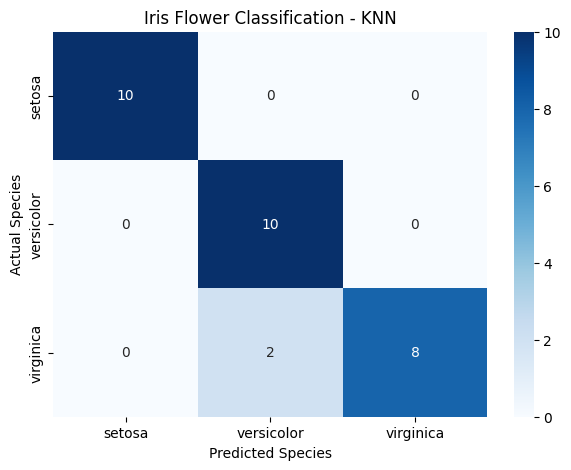


NEW FLOWER DETAILS:
[[5.1, 3.5, 1.4, 0.2]]

Predicted Flower Species: setosa


In [2]:

# IRIS FLOWER CLASSIFICATION USING K-NEAREST NEIGHBOURS (KNN)

# Step 1: Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

# Step 2: Load the Iris dataset
iris = load_iris()

X = iris.data
y = iris.target

# Display dataset
df = pd.DataFrame(X, columns=iris.feature_names)
df['Species'] = iris.target_names[y]

print("IRIS DATASET")
print(df.head())

# Step 3: Split the dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Step 4: Feature scaling
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Step 5: Create KNN classifier
knn = KNeighborsClassifier(n_neighbors=5)

# Step 6: Train the model
knn.fit(X_train, y_train)

print("\nKNN Model Training Completed Successfully!")

# Step 7: Predict the test data
y_pred = knn.predict(X_test)

print("\nPredicted Values:")
print(y_pred)

print("\nActual Values:")
print(y_test)

# Step 8: Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("\nModel Accuracy: {:.2f}%".format(accuracy * 100))

# Step 9: Display classification report
print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names
))

# Step 10: Display confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.title("Iris Flower Classification - KNN")
plt.show()

# Step 11: Predict a new flower
new_flower = [[5.1, 3.5, 1.4, 0.2]]

new_flower_scaled = scaler.transform(new_flower)

prediction = knn.predict(new_flower_scaled)

print("\nNEW FLOWER DETAILS:")
print(new_flower)

print("\nPredicted Flower Species:",
      iris.target_names[prediction[0]])
